# 06 — EV Charging Demand Time-Series Analysis and Forecasting

## Objective
Analyze how recorded EV charging demand changes over time and compare simple forecasting methods to estimate demand in future time intervals.

## Scope
This notebook will:
1. Aggregate session-level `Demand` into an hourly time series.
2. Examine time coverage, session activity, and demand patterns.
3. Create a chronological training and test split.
4. Establish a Moving Average forecasting baseline.
5. Apply Exponential Smoothing.
6. Compare forecasts using MAE and RMSE.
7. Summarize observed patterns, forecasting results, and limitations.

## Aggregation Definition
The primary time-series target is the sum of recorded `Demand` for sessions whose `StartDatetime` falls within each hour. An hour without any session starts receives an aggregate value of zero.

This represents aggregate recorded demand associated with session start times. The GUVI brief does not specify the physical definition or units of `Demand`, so the results must not be interpreted as energy consumption or electrical load in a specific unit without further evidence.

## Evaluation Strategy
Observations will be sorted chronologically. Earlier hourly observations will be used for training and later observations for testing. Forecasting methods will be compared on the same held-out time window using MAE and RMSE.

The actual duration of individual sessions will not be used in the time-series target or forecasting inputs.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Paths are relative to the notebooks/ directory.
DATA_PATH = Path("../data/processed/ev_charging_features.csv")
REPORTS_DIR = Path("../reports")

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Ensure the expected dataset is available.
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

# Load the engineered dataset produced by Notebook 02.
ts_df = pd.read_csv(DATA_PATH)

# Convert timestamps and target to suitable data types.
ts_df["StartDatetime"] = pd.to_datetime(
    ts_df["StartDatetime"],
    errors="coerce",
)

ts_df["Demand"] = pd.to_numeric(
    ts_df["Demand"],
    errors="coerce",
)

# Retain records with a usable timestamp and target.
rows_before = len(ts_df)

ts_df = ts_df.dropna(
    subset=["StartDatetime", "Demand"]
).copy()

rows_removed = rows_before - len(ts_df)

# Sort from oldest to newest before creating the time series.
ts_df = (
    ts_df.sort_values("StartDatetime")
         .reset_index(drop=True)
)

print("Dataset loaded successfully.")
print(f"Dataset shape: {ts_df.shape}")
print(f"Rows excluded for missing timestamp/target: {rows_removed}")
print(f"First timestamp: {ts_df['StartDatetime'].min()}")
print(f"Last timestamp:  {ts_df['StartDatetime'].max()}")
print(f"Missing Demand after validation: {ts_df['Demand'].isna().sum()}")

Dataset loaded successfully.
Dataset shape: (72826, 24)
Rows excluded for missing timestamp/target: 0
First timestamp: 2021-09-30 17:14:26
Last timestamp:  2022-09-30 23:11:59
Missing Demand after validation: 0


In [2]:
# Use session start time as the time index.
indexed_demand = ts_df.set_index("StartDatetime")["Demand"]
indexed_demand = indexed_demand.sort_index()

# Sum the recorded Demand values for all sessions beginning in each hour.
# min_count=1 preserves empty hours as missing temporarily.
hourly_demand = (
    indexed_demand
    .resample("1h")
    .sum(min_count=1)
    .rename("HourlyDemand")
    .to_frame()
)

# Count session starts in each hour.
hourly_sessions = (
    ts_df
    .set_index("StartDatetime")
    .resample("1h")
    .size()
    .rename("SessionCount")
)

hourly_demand["SessionCount"] = hourly_sessions

# An hour without session starts has a total aggregate Demand of zero.
hourly_demand["SessionCount"] = (
    hourly_demand["SessionCount"].fillna(0).astype(int)
)

hourly_demand["HourlyDemand"] = (
    hourly_demand["HourlyDemand"].fillna(0)
)

print("Hourly time series created.")
print(f"Hourly observations: {len(hourly_demand):,}")
print(f"First hour: {hourly_demand.index.min()}")
print(f"Last hour:  {hourly_demand.index.max()}")
print(
    "Hours without session starts:",
    (hourly_demand["SessionCount"] == 0).sum(),
)

print("\nHourly aggregate-demand summary:")
display(hourly_demand["HourlyDemand"].describe().round(3))

print("\nHourly session-count summary:")
display(hourly_demand["SessionCount"].describe().round(3))

print("\nFirst 10 hourly observations:")
display(hourly_demand.head(10).round(3))

Hourly time series created.
Hourly observations: 8,767
First hour: 2021-09-30 17:00:00
Last hour:  2022-09-30 23:00:00
Hours without session starts: 988

Hourly aggregate-demand summary:


count    8767.000
mean      144.874
std       122.197
min         0.000
25%        45.460
50%       122.570
75%       215.230
max       745.550
Name: HourlyDemand, dtype: float64


Hourly session-count summary:


count    8767.000
mean        8.307
std         6.499
min         0.000
25%         2.000
50%         8.000
75%        13.000
max        38.000
Name: SessionCount, dtype: float64


First 10 hourly observations:


,HourlyDemand,SessionCount
StartDatetime,,
2021-09-30 17:00:00,27.68,1
2021-09-30 18:00:00,93.58,2
2021-09-30 19:00:00,30.17,1
2021-09-30 20:00:00,47.00,1
2021-09-30 21:00:00,117.54,4
2021-09-30 22:00:00,148.00,5
2021-09-30 23:00:00,115.22,5
2021-10-01 00:00:00,18.18,1
2021-10-01 01:00:00,0.00,0


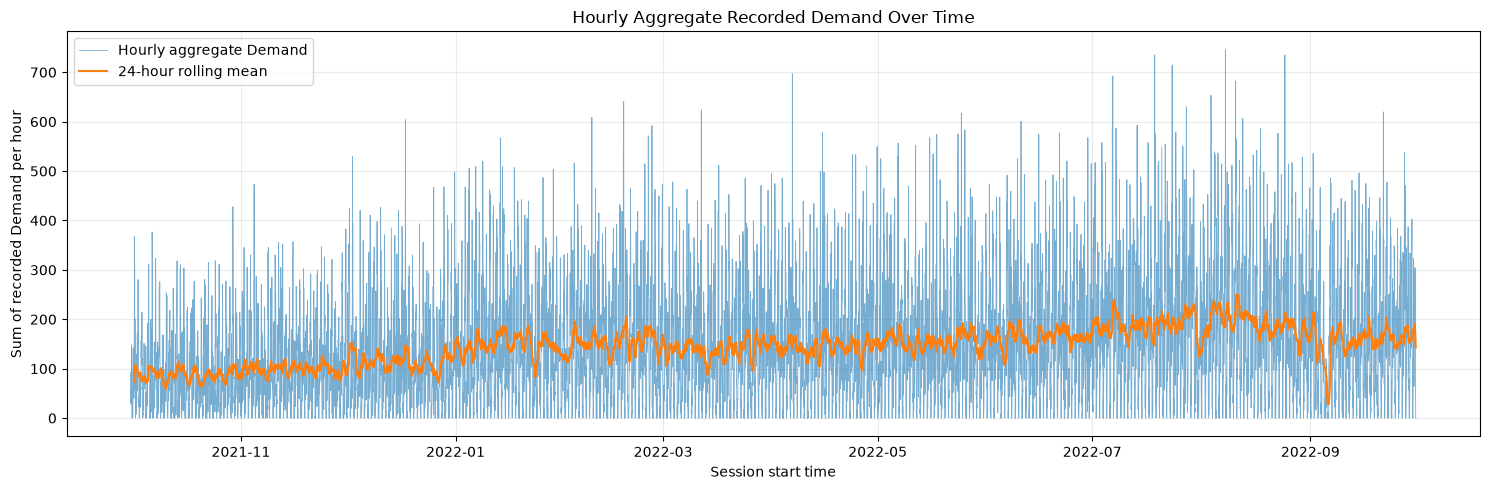

In [3]:
# A 24-hour rolling mean helps reveal the broader pattern
# without changing the underlying hourly series.
hourly_demand["RollingMean24h"] = (
    hourly_demand["HourlyDemand"]
    .rolling(window=24, min_periods=24)
    .mean()
)

plt.figure(figsize=(15, 5))

plt.plot(
    hourly_demand.index,
    hourly_demand["HourlyDemand"],
    linewidth=0.6,
    alpha=0.6,
    label="Hourly aggregate Demand",
)

plt.plot(
    hourly_demand.index,
    hourly_demand["RollingMean24h"],
    linewidth=1.5,
    label="24-hour rolling mean",
)

plt.title("Hourly Aggregate Recorded Demand Over Time")
plt.xlabel("Session start time")
plt.ylabel("Sum of recorded Demand per hour")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [7]:


# Reserve the final 20% of hourly observations for testing.
TEST_SIZE = 0.20

# Use hourly aggregate Demand as the forecasting target.
y_hourly = hourly_demand["HourlyDemand"].astype(float).copy()

# Check for missing values before splitting.
if y_hourly.isna().any():
    raise ValueError("Hourly demand contains missing values.")

# Confirm observations are consistently spaced one hour apart.
time_differences = y_hourly.index.to_series().diff().dropna()

if not time_differences.eq(pd.Timedelta(hours=1)).all():
    raise ValueError(
        "The time series is not consistently spaced at hourly intervals."
    )

# Calculate the chronological split position.
split_index = int(len(y_hourly) * (1 - TEST_SIZE))

# Earlier observations are used for training.
train_series = y_hourly.iloc[:split_index].copy()

# Later observations are reserved for testing.
test_series = y_hourly.iloc[split_index:].copy()

# Confirm that training data occurs strictly before testing data.
assert train_series.index.max() < test_series.index.min()

# Display split details.
print("Chronological time-series split completed.")
print(f"Test set proportion: {TEST_SIZE:.0%}")
print(f"Total hourly observations: {len(y_hourly):,}")
print(f"Training observations: {len(train_series):,}")
print(f"Testing observations: {len(test_series):,}")

print("\nTraining period:")
print(f"{train_series.index.min()} to {train_series.index.max()}")

print("\nTesting period:")
print(f"{test_series.index.min()} to {test_series.index.max()}")

print("\nTraining aggregate-demand summary:")
display(train_series.describe().round(3))

print("\nTesting aggregate-demand summary:")
display(test_series.describe().round(3))

Chronological time-series split completed.
Test set proportion: 20%
Total hourly observations: 8,767
Training observations: 7,013
Testing observations: 1,754

Training period:
2021-09-30 17:00:00 to 2022-07-19 21:00:00

Testing period:
2022-07-19 22:00:00 to 2022-09-30 23:00:00

Training aggregate-demand summary:


count    7013.000
mean      136.963
std       116.548
min         0.000
25%        42.220
50%       116.280
75%       203.400
max       735.200
Name: HourlyDemand, dtype: float64


Testing aggregate-demand summary:


count    1754.000
mean      176.504
std       138.144
min         0.000
25%        61.355
50%       159.130
75%       262.572
max       745.550
Name: HourlyDemand, dtype: float64

In [8]:
#  Moving Average and Exponential Smoothing forecasts

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.holtwinters import SimpleExpSmoothing

# Forecasting configuration.
MA_WINDOW = 24  # Use the previous 24 observed hours.

# ---------------------------------------------------------
# 1. Moving Average — rolling one-step-ahead forecast
# ---------------------------------------------------------

# Start with training observations only.
history = train_series.astype(float).tolist()
moving_average_predictions = []

for actual_value in test_series.to_numpy():
    # Predict the next hour using the previous 24 observed hours.
    prediction = float(np.mean(history[-MA_WINDOW:]))
    moving_average_predictions.append(prediction)

    # After making the prediction, the actual value becomes
    # available for the next hour's forecast.
    history.append(float(actual_value))


# ---------------------------------------------------------
# 2. Simple Exponential Smoothing — rolling one-step-ahead
# ---------------------------------------------------------

# Fit and optimize the smoothing parameter using training data only.
ses_model = SimpleExpSmoothing(
    train_series.astype(float),
    initialization_method="estimated",
)

ses_fit = ses_model.fit(optimized=True)

# Retrieve the smoothing weight learned from the training period.
alpha = float(ses_fit.params["smoothing_level"])

# The fitted model's next-step forecast initializes the rolling state.
level = float(ses_fit.forecast(1).iloc[0])

exponential_smoothing_predictions = []

for actual_value in test_series.to_numpy():
    # Predict the next hour using the current smoothed level.
    prediction = level
    exponential_smoothing_predictions.append(prediction)

    # Update the level only after the actual value is observed.
    level = (
        alpha * float(actual_value)
        + (1 - alpha) * level
    )


# ---------------------------------------------------------
# 3. Evaluate both methods on the same test observations
# ---------------------------------------------------------

forecast_df = pd.DataFrame(
    {
        "ActualDemand": test_series.to_numpy(),
        "MovingAverage24h": moving_average_predictions,
        "ExponentialSmoothing": exponential_smoothing_predictions,
    },
    index=test_series.index,
)

forecast_results = []

for method in [
    "MovingAverage24h",
    "ExponentialSmoothing",
]:
    actual = forecast_df["ActualDemand"]
    predicted = forecast_df[method]

    forecast_results.append({
        "Method": method,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    })

forecast_metrics_df = (
    pd.DataFrame(forecast_results)
    .sort_values("MAE")
    .reset_index(drop=True)
)

print(f"Moving Average window: {MA_WINDOW} hours")
print(f"Learned smoothing alpha: {alpha:.4f}")
print(f"Forecast observations evaluated: {len(forecast_df):,}")

display(forecast_metrics_df.round(4))

Moving Average window: 24 hours
Learned smoothing alpha: 0.6737
Forecast observations evaluated: 1,754


,Method,MAE,RMSE
0,ExponentialSmoothing,81.2079,107.6907
1,MovingAverage24h,110.7353,136.6587


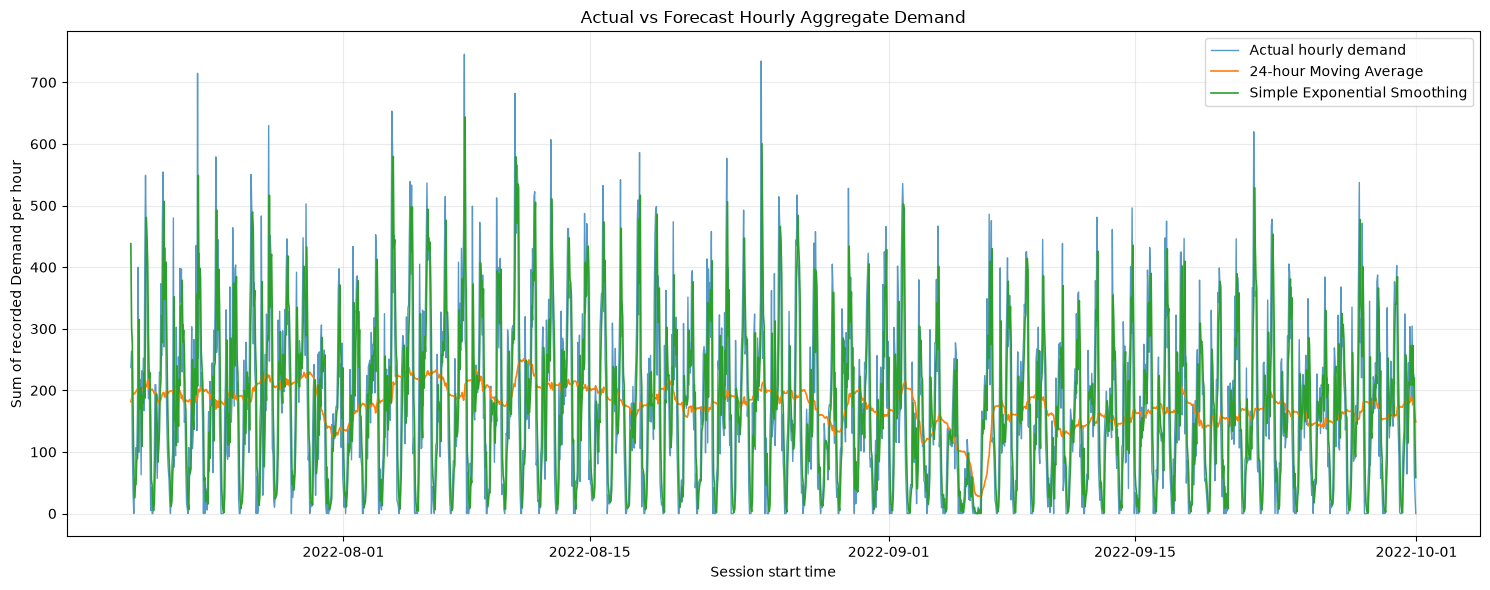

In [9]:
# Compare actual demand with both rolling forecasts

plt.figure(figsize=(15, 6))

plt.plot(
    forecast_df.index,
    forecast_df["ActualDemand"],
    label="Actual hourly demand",
    linewidth=1.0,
    alpha=0.75,
)

plt.plot(
    forecast_df.index,
    forecast_df["MovingAverage24h"],
    label="24-hour Moving Average",
    linewidth=1.2,
)

plt.plot(
    forecast_df.index,
    forecast_df["ExponentialSmoothing"],
    label="Simple Exponential Smoothing",
    linewidth=1.2,
)

plt.title("Actual vs Forecast Hourly Aggregate Demand")
plt.xlabel("Session start time")
plt.ylabel("Sum of recorded Demand per hour")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [10]:
# Cell 8: Save forecast metrics and test-period predictions

REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# Save the evaluation metrics.
forecast_metrics_df.to_csv(
    REPORTS_DIR / "time_series_forecast_comparison.csv",
    index=False,
)

# Save actual values and both methods' predictions.
forecast_df.to_csv(
    REPORTS_DIR / "time_series_test_forecasts.csv",
    index_label="StartDatetime",
)

print("Forecast artifacts saved.")

for path in [
    REPORTS_DIR / "time_series_forecast_comparison.csv",
    REPORTS_DIR / "time_series_test_forecasts.csv",
]:
    if not path.exists() or path.stat().st_size == 0:
        raise RuntimeError(f"Artifact missing or empty: {path}")

    print(f"Verified: {path.resolve()}")

Forecast artifacts saved.
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\time_series_forecast_comparison.csv
Verified: E:\GUVI Projects\Ev_Charging_Demand_Project2\Ev_Charging_Demand_Prediction\reports\time_series_test_forecasts.csv


In [11]:
from statsmodels.tsa.stattools import adfuller

# Test the training series only; keep the test period out of
# this diagnostic to preserve our forecasting evaluation design.
adf_result = adfuller(
    train_series,
    regression="c",
    autolag="AIC",
)

adf_statistic = adf_result[0]
p_value = adf_result[1]
critical_values = adf_result[4]

print("Augmented Dickey-Fuller (ADF) Test")
print(f"ADF statistic: {adf_statistic:.4f}")
print(f"p-value: {p_value:.6f}")
print("\nCritical values:")

for level, value in critical_values.items():
    print(f"{level}: {value:.4f}")

if p_value < 0.05:
    print(
        "\nInterpretation: Reject the unit-root null hypothesis "
        "at the 5% significance level."
    )
else:
    print(
        "\nInterpretation: Fail to reject the unit-root null "
        "hypothesis at the 5% significance level."
    )

Augmented Dickey-Fuller (ADF) Test
ADF statistic: -6.2718
p-value: 0.000000

Critical values:
1%: -3.4313
5%: -2.8620
10%: -2.5670

Interpretation: Reject the unit-root null hypothesis at the 5% significance level.


C:\Users\Trinetra\AppData\Local\Temp\ipykernel_30940\1384738241.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(


In [12]:
adf_result = adfuller(
    train_series,
    regression="c",
    autolag="AIC",
    result_object=True,
)

print(f"ADF statistic: {adf_result.statistic:.4f}")
print(f"p-value: {adf_result.pvalue:.8f}")
print("Critical values:", adf_result.critical_values)

ADF statistic: -6.2718
p-value: 0.00000004
Critical values: {'1%': np.float64(-3.4312873415742224), '5%': np.float64(-2.861954229474028), '10%': np.float64(-2.5669904903987955)}


# Time-Series Analysis — Summary, Results, and Conclusions

## 1. Objective

The objective was to analyze hourly EV charging demand patterns and compare simple forecasting methods using a chronological evaluation strategy.

The analysis followed the GUVI requirement to aggregate demand over time, inspect temporal behavior, apply Moving Average and Exponential Smoothing methods, and evaluate forecasts using MAE and RMSE.

## 2. Time-series construction

The input dataset was `data/processed/ev_charging_features.csv`.

The `Demand` values were aggregated by session start hour:
- `HourlyDemand`: sum of recorded `Demand` for sessions whose `StartDatetime` falls within each hour.
- `SessionCount`: number of sessions starting in each hour.

Hours without session starts were assigned zero aggregate demand and zero session count.

The resulting hourly series contained 8,767 observations from 2021-09-30 17:00 to 2022-09-30 23:00.

The hourly aggregate demand had a mean of 144.874, median of 122.570, standard deviation of 122.197, and maximum of 745.550. There were 988 hours without session starts, approximately 11.27% of the series.

The target represents aggregate recorded demand by session-start hour. The GUVI project brief does not specify the physical definition or units of `Demand`, so these results must not be interpreted as electrical load or energy in a particular unit.

## 3. Visual analysis

The hourly plot shows substantial short-term variation, including repeated drops toward zero when no sessions started during an hour.

The 24-hour rolling mean appears to rise from late 2021 into mid-2022, reach higher levels around July–August, and decline toward September. This is a descriptive observation and not, by itself, statistical proof of seasonality or a long-term trend.

The number of session starts also varied considerably: the hourly mean was 8.307 sessions, and the maximum observed hourly count was 38.

## 4. Chronological train-test split

The earliest 80% of hourly observations were used for training, and the final 20% were reserved for testing.

| Split detail | Result |
|---|---|
| Training observations | 7,013 |
| Testing observations | 1,754 |
| Training period | 2021-09-30 17:00 to 2022-07-19 21:00 |
| Testing period | 2022-07-19 22:00 to 2022-09-30 23:00 |
| Training mean hourly aggregate | 136.963 |
| Test mean hourly aggregate | 176.504 |

The test-period mean was approximately 28.9% higher than the training-period mean. This difference in average levels makes forecasting later observations more challenging for methods that rely on previous values.

The data was not shuffled, preserving chronological order.

## 5. Forecasting methods

### 5.1 Moving Average

A 24-hour Moving Average forecast used the mean of the previous 24 observed hourly aggregate values to predict the next hour.

### 5.2 Simple Exponential Smoothing

Simple Exponential Smoothing was fitted using the training series. The learned smoothing parameter was alpha = 0.6737, indicating that recent observations have considerable influence on the next prediction.

### 5.3 Evaluation protocol

Both methods were evaluated using rolling one-step-ahead forecasts over the same 1,754-hour test window. Each prediction was produced before its corresponding actual value was used to update the forecast for the following hour.

These results therefore represent rolling one-hour-ahead forecasting, not a fixed multi-hour forecast of the entire test period made in advance.

## 6. Forecast comparison

| Method | MAE | RMSE |
|---|---:|---:|
| **Simple Exponential Smoothing** | **81.2079** | **107.6907** |
| 24-hour Moving Average | 110.7353 | 136.6587 |

Simple Exponential Smoothing outperformed the 24-hour Moving Average on both metrics.

Relative to the Moving Average, it reduced MAE by approximately 26.7% and RMSE by approximately 21.2%.

The actual-versus-forecast visualization shows that Exponential Smoothing responds more quickly to changing hourly values, while the Moving Average is smoother and reacts more slowly. Both methods still miss some sharp peaks, and their forecast errors remain substantial.

## 7. Stationarity diagnostic — Augmented Dickey-Fuller test

The Augmented Dickey-Fuller test was performed on the training series only, with a constant term and AIC-based lag selection.

| Diagnostic | Result |
|---|---:|
| ADF statistic | -6.2718 |
| Displayed p-value | 0.000000, rounded to six decimal places |
| 1% critical value | -3.4313 |
| 5% critical value | -2.8620 |
| 10% critical value | -2.5670 |

The statistic is more negative than all three critical values, and the displayed p-value is below 0.05. The unit-root null hypothesis is therefore rejected at the 5% significance level.

This provides evidence against a unit root in the training series. It does not establish that all trend, seasonal structure, or changing variance are absent. The ADF result should not be used as proof that the series is suitable for every forecasting method without further diagnostics.

## 8. Saved artifacts

The user reported that the forecasting outputs were saved in the following files:

- `reports/time_series_forecast_comparison.csv`
- `reports/time_series_test_forecasts.csv`

The forecast comparison file contains the evaluation metrics, and the test forecast file contains actual hourly aggregate demand alongside the Moving Average and Exponential Smoothing predictions.

## 9. Limitations

1. The physical meaning and units of `Demand` are not specified in the GUVI brief.
2. Zero aggregate demand means no session starts were recorded in that hour under the chosen aggregation definition. It does not prove that an EV station or the electricity grid experienced no load.
3. The test-period mean was higher than the training-period mean, and both simple methods missed some abrupt demand peaks.
4. Only one chronological holdout and rolling one-step-ahead forecasts were evaluated. Results may differ for forecasts made several hours or days ahead.
5. The ADF test assesses evidence against a unit root; it does not independently confirm daily seasonality or rule out other forms of non-stationarity.

## 10. Conclusion and next steps

Simple Exponential Smoothing was the stronger of the two evaluated forecasting methods, achieving MAE = 81.2079 and RMSE = 107.6907. The rolling one-step-ahead evaluation and ADF diagnostic complete the time-series analysis planned for the current project scope.

The next major stage is the manual-entry Streamlit dashboard. It will integrate the saved regression and classification pipelines, display the forecasting results, and derive temporal features from user-entered date/time values. Models will be loaded from saved artifacts rather than retrained inside the application.